In [1]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms

from PIL import Image
import cv2
import matplotlib.pyplot as plt

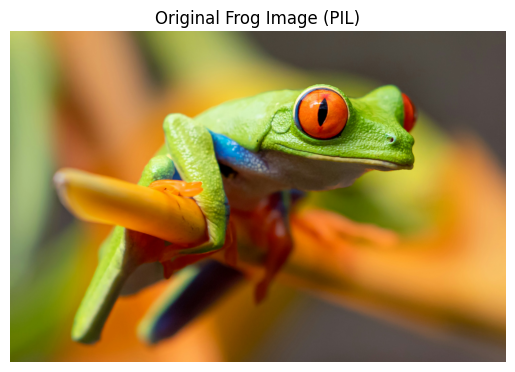

In [2]:
image_pil = Image.open("frog.jpg")


plt.imshow(image_pil)
plt.title("Original Frog Image (PIL)")
plt.axis("off")
plt.show()

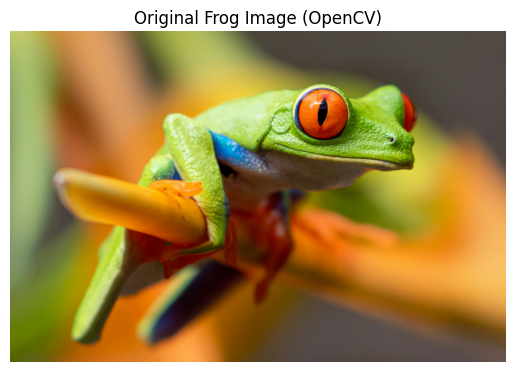

In [3]:
image_cv = cv2.imread("frog.jpg")

image_cv = cv2.cvtColor(image_cv, cv2.COLOR_BGR2RGB)

plt.imshow(image_cv)
plt.title("Original Frog Image (OpenCV)")
plt.axis("off")
plt.show()

In [4]:
transform = transforms.ToTensor()

image_tensor = transform(image_pil)

print("Tensor Shape:", image_tensor.shape)

Tensor Shape: torch.Size([3, 1958, 2937])


In [ ]:
image_tensor = image_tensor.unsqueeze(0)

print("New Tensor Shape:", image_tensor.shape)

New Tensor Shape: torch.Size([1, 3, 1958, 2937])


In [ ]:
conv_layer = nn.Conv2d(
    in_channels=3,
    out_channels=1,
    kernel_size=3,
    stride=1,
    padding=0
)

conv_output = conv_layer(image_tensor)

print("Convolution Output Shape:", conv_output.shape)

Convolution Output Shape: torch.Size([1, 1, 1956, 2935])


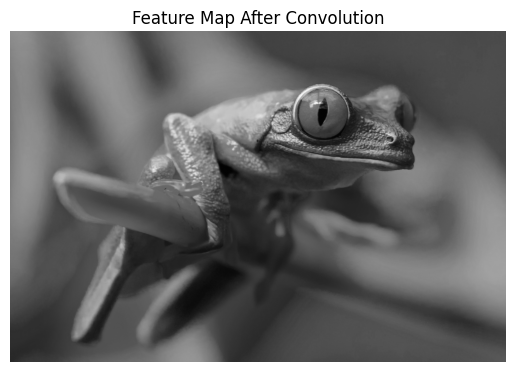

In [ ]:
conv_image = conv_output.squeeze(0).squeeze(0).detach().numpy()

plt.imshow(conv_image, cmap='gray')
plt.title("Feature Map After Convolution")
plt.axis("off")
plt.show()

In [ ]:
pool_layer = nn.MaxPool2d(kernel_size=2)

pool_output = pool_layer(conv_output)

print("Pooling Output Shape:", pool_output.shape)

Pooling Output Shape: torch.Size([1, 1, 978, 1467])


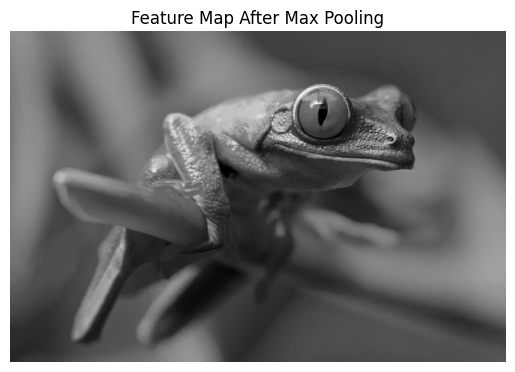

In [9]:
pool_image = pool_output.squeeze(0).squeeze(0).detach().numpy()

plt.imshow(pool_image, cmap='gray')
plt.title("Feature Map After Max Pooling")
plt.axis("off")
plt.show()

In [10]:
print("Original Image Tensor Shape :", image_tensor.shape)
print("After Convolution Shape     :", conv_output.shape)
print("After Max Pooling Shape     :", pool_output.shape)

Original Image Tensor Shape : torch.Size([1, 3, 1958, 2937])
After Convolution Shape     : torch.Size([1, 1, 1956, 2935])
After Max Pooling Shape     : torch.Size([1, 1, 978, 1467])


In [ ]:
# Observations and Explanation

## How convolution changes the image
Convolution applies filters on the image and extracts important patterns such as edges, textures, and shapes.

## What features are highlighted after convolution
The convolution layer highlights edges, boundaries, and texture information of the frog image.

## How max pooling reduces spatial dimensions
Max pooling selects the maximum values from small regions and reduces image width and height.

## Why pooling helps CNNs focus on important features
Pooling removes unnecessary details while keeping important features, making CNN models faster and more efficient.